# Timestral tutorial: forecasting with Mistral's time-series foundation models

Timestral is a family of pretrained forecasting models (5M, 28M, 123M, 209M parameters) released by Mistral AI in
October 2026. It is **zero-shot**: you do not train it, you pass it a history and it returns a probabilistic
forecast. It runs on CPU.

**What you will learn**

1. Install, load a model, choose a size
2. Your first forecast, and how to read the output (quantiles, median, intervals)
3. Input shapes, batches of series, missing values, series of different lengths
4. Working from pandas DataFrames (timestamps in, tidy forecast table out)
5. Multivariate series forecast jointly
6. Covariates: past-only, known-future, categorical (promotions, holidays, weather forecasts…)
7. Long horizons, forecaster options (`symmetric_averaging`, `clip_nonnegative`, context length)
8. Backtesting: measure accuracy (MASE, WQL) and speed, compare model sizes with a baseline
9. Offline / air-gapped use, practical tips and pitfalls

**Requirements**: Python ≥ 3.10, PyTorch ≥ 2.4, internet access to `huggingface.co` (weights) and
`raw.githubusercontent.com` (two small public demo datasets). Licence reminder: the code is Apache-2.0, the weights
are under a *Modified MIT* licence (see each model card on Hugging Face).

## 1. Install and load

In [1]:
# Run once (uncomment). The commit is pinned to the version used for Mistral's benchmark submissions.
%pip install -q "timestral @ git+https://github.com/mistralai/timestral@a534bdbd244d64f3d9d743f46c7bf6fc330ed4ff" \
                pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


c:\Users\Stefan.Duprey\Documents\GitHub\timestral_prophet\.venv\Scripts\python.exe: No module named pip


In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from timestral import TimestralForecaster

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(0)

c:\Users\Stefan.Duprey\Documents\GitHub\timestral_prophet\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Four sizes share the same architecture and training recipe. Weights are downloaded once to the Hugging Face cache.

| Model | Hub id | fp32 weights | When to use |
|---|---|---|---|
| Timestral-5M | `mistralai/Timestral-5M` | 21 MB | edge devices, millions of series, latency-critical |
| Timestral-28M | `mistralai/Timestral-28M` | 111 MB | good default for large batch jobs on CPU |
| Timestral-123M | `mistralai/Timestral-123M` | 490 MB | within ~0.2% of 209M at ~¾ of its latency |
| Timestral-209M | `mistralai/Timestral-209M` | 837 MB | best accuracy |

In [3]:
MODEL_ID = "mistralai/Timestral-28M"   # switch to Timestral-209M for best accuracy
device = "cuda" if torch.cuda.is_available() else "cpu"

forecaster = TimestralForecaster.from_pretrained(MODEL_ID, device=device)
cfg = forecaster.config
print(f"{MODEL_ID} on {device}")
print(f"patch size: {cfg.patch_size} steps | max context: {forecaster.max_context} steps | "
      f"steps decoded per block: {cfg.block_size * cfg.patch_size}")
print("quantile levels:", forecaster.quantile_levels)

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 433.56it/s]


mistralai/Timestral-28M on cpu
patch size: 32 steps | max context: 32768 steps | steps decoded per block: 1024
quantile levels: (0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99)


## 2. Your first forecast

The model only sees **numbers in order**. There is no frequency or date argument: seasonality, trend and scale are
inferred from the history itself. So give it enough history to show the patterns you care about (for example
several weeks of hourly data to capture weekly seasonality).

In [4]:
# A synthetic hourly series: daily + weekly seasonality, trend, noise. Six weeks of history.
T, H = 24 * 7 * 6, 48
t = np.arange(T + H)
signal = 100 + 0.05 * t + 15 * np.sin(2 * np.pi * t / 24) + 8 * np.sin(2 * np.pi * t / 168)
y = signal + rng.normal(0, 3, t.size)
history, future = y[:T], y[T:]

fc = forecaster.forecast(history, prediction_length=H)

print("quantiles:", tuple(fc.quantiles.shape), "-> (series, variates, horizon, quantile levels)")
print("median   :", tuple(fc.median.shape))

quantiles: (1, 1, 48, 21) -> (series, variates, horizon, quantile levels)
median   : (1, 1, 48)


`Forecast` holds 21 quantiles per step. The **median** (`fc.median`) is the point forecast; pairs of quantiles give
prediction intervals: (0.1, 0.9) is an 80% interval and (0.05, 0.95) a 90% interval.

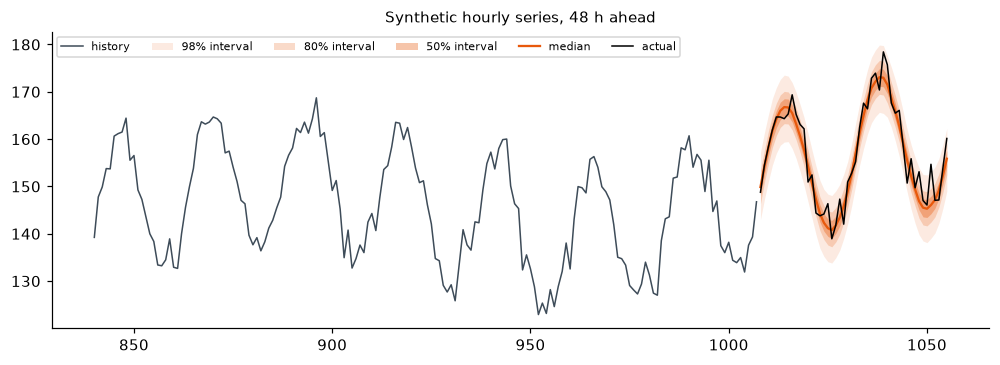

In [5]:
def plot_forecast(history, fc, future=None, series=0, variate=0, n_hist=None, title="", ax=None):
    """Fan chart: history, median, 50% / 80% / 98% intervals, and the truth if given."""
    ax = ax or plt.subplots(figsize=(11, 3.5))[1]
    hist = np.asarray(history)
    n_hist = n_hist or len(hist)
    x_hist = np.arange(len(hist))[-n_hist:]
    x_fut = np.arange(len(hist), len(hist) + fc.quantiles.shape[2])
    q = lambda p: fc.quantile(p)[series, variate].cpu().numpy()  # noqa: E731
    ax.plot(x_hist, hist[-n_hist:], color="#3e4c59", lw=1, label="history")
    for lo, hi, a in [(0.01, 0.99, 0.12), (0.1, 0.9, 0.22), (0.25, 0.75, 0.35)]:
        ax.fill_between(x_fut, q(lo), q(hi), color="#e8590c", alpha=a, lw=0,
                        label=f"{int(round((hi - lo) * 100))}% interval")
    ax.plot(x_fut, q(0.5), color="#e8590c", lw=1.5, label="median")
    if future is not None:
        ax.plot(x_fut, future, color="black", lw=1, label="actual")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, ncol=6, loc="upper left")
    return ax


plot_forecast(history, fc, future, n_hist=24 * 7, title="Synthetic hourly series, 48 h ahead")
plt.show()

In [6]:
# Using the numbers: point forecast, an interval, and the empirical coverage on this example
median = fc.median[0, 0].numpy()
lo80, hi80 = fc.quantile(0.1)[0, 0].numpy(), fc.quantile(0.9)[0, 0].numpy()
print(f"MAE of the median: {np.mean(np.abs(future - median)):.2f}")
print(f"80% interval covers {np.mean((future >= lo80) & (future <= hi80)):.0%} of the 48 actual values")

MAE of the median: 2.29
80% interval covers 75% of the 48 actual values


## 3. Input shapes, batches, missing values

`context` accepts a NumPy array or a torch tensor:

| Shape | Meaning |
|---|---|
| `(T,)` | one series |
| `(B, T)` | B independent univariate series |
| `(B, V, T)` | B series, each with V variates forecast **jointly** |

**NaN = missing.** Use it for gaps, and to **left-pad** series of different lengths into one batch.
You can also pass `observation_mask` (same shape, `False` = treat as missing) to hide values that are present but
wrong (outliers, stock-outs…). Contexts longer than the cap (32,768 steps) are truncated to the most recent steps.

batch context: (3, 1000) -> quantiles (3, 1, 24, 21)


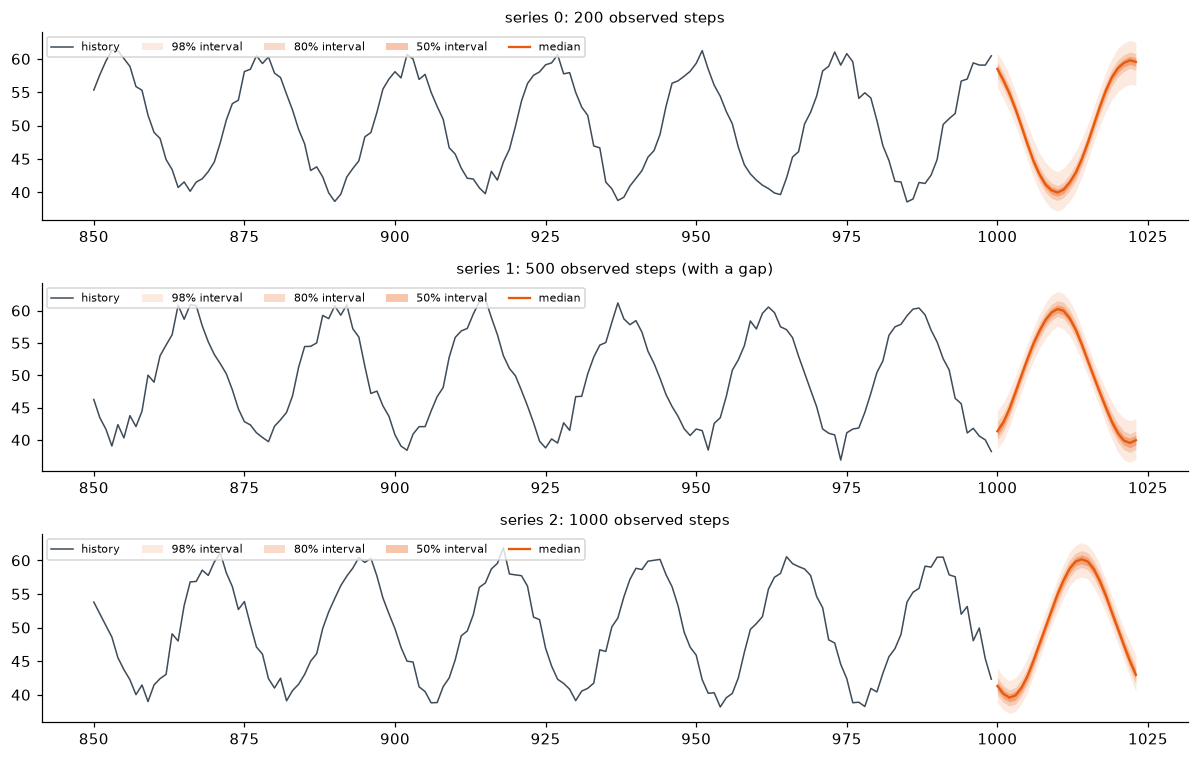

In [7]:
def pad_left(series_list):
    """Stack series of different lengths into (B, T_max), left-padded with NaN."""
    T_max = max(len(s) for s in series_list)
    out = np.full((len(series_list), T_max), np.nan, dtype=np.float32)
    for i, s in enumerate(series_list):
        out[i, T_max - len(s):] = s
    return out


lengths = [200, 500, 1000]
batch_series = [50 + 10 * np.sin(2 * np.pi * np.arange(n) / 24) + rng.normal(0, 1, n) for n in lengths]
batch = pad_left(batch_series)
batch[1, 300:340] = np.nan                       # a 40-step gap in series 1

fc_batch = forecaster.forecast(batch, prediction_length=24)
print("batch context:", batch.shape, "-> quantiles", tuple(fc_batch.quantiles.shape))

fig, axes = plt.subplots(3, 1, figsize=(11, 7))
for i, ax in enumerate(axes):
    plot_forecast(batch[i], fc_batch, series=i, n_hist=150, ax=ax,
                  title=f"series {i}: {lengths[i]} observed steps" + (" (with a gap)" if i == 1 else ""))
plt.tight_layout()
plt.show()

In [8]:
# observation_mask: ignore suspicious values without deleting them
spiky = batch_series[2].copy()
spiky[-30:-25] = 500                              # sensor glitch near the end
mask = np.ones_like(spiky, dtype=bool)
mask[-30:-25] = False
fc_raw = forecaster.forecast(spiky, 24)
fc_masked = forecaster.forecast(spiky, 24, observation_mask=mask)
print("median, first 5 steps, glitch included:", fc_raw.median[0, 0, :5].numpy().round(1))
print("median, first 5 steps, glitch masked  :", fc_masked.median[0, 0, :5].numpy().round(1))

median, first 5 steps, glitch included: [40.4 39.3 38.6 38.7 40. ]
median, first 5 steps, glitch masked  : [41.4 40.2 39.6 39.9 41. ]


## 4. From pandas to pandas

Real data comes with timestamps and ids. Timestral ignores timestamps, so the workflow is:
**regularise each series to a fixed frequency → array → forecast → rebuild future timestamps**.
The two helpers below do this for a long-format DataFrame (`id`, `timestamp`, `value`).

In [9]:
QUANTILES_OUT = (0.1, 0.5, 0.9)


def frame_to_context(df, freq, id_col="id", time_col="timestamp", value_col="value"):
    """Long DataFrame -> (context (B, T) NaN-padded, ids, last timestamp per series).

    Each series is reindexed to a regular `freq` grid, so missing timestamps become NaN.
    """
    series, ids, last_ts = [], [], []
    for sid, g in df.groupby(id_col, sort=True):
        s = g.set_index(time_col)[value_col].sort_index()
        s = s[~s.index.duplicated(keep="last")]
        s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq=freq))
        series.append(s.to_numpy(dtype=np.float32))
        ids.append(sid)
        last_ts.append(s.index.max())
    return pad_left(series), ids, last_ts


def forecast_to_frame(fc, ids, last_ts, freq, quantiles=QUANTILES_OUT, variate=0):
    """Forecast -> tidy DataFrame with one row per (id, future timestamp)."""
    H = fc.quantiles.shape[2]
    rows = []
    for b, (sid, ts) in enumerate(zip(ids, last_ts)):
        future_idx = pd.date_range(ts, periods=H + 1, freq=freq)[1:]
        d = {"id": sid, "timestamp": future_idx}
        for q in quantiles:
            d[f"q{q:g}"] = fc.quantile(q)[b, variate].cpu().numpy()
        rows.append(pd.DataFrame(d))
    return pd.concat(rows, ignore_index=True)


# Public dataset: daily minimum temperatures in Melbourne, 1981-1990
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
temps = pd.read_csv(url, parse_dates=["Date"]).rename(columns={"Date": "timestamp", "Temp": "value"})
temps["id"] = "melbourne"
temps.tail(3)

,timestamp,value,id
3647,1990-12-29,13.5,melbourne
3648,1990-12-30,15.7,melbourne
3649,1990-12-31,13.0,melbourne


          id  timestamp       q0.1       q0.5       q0.9
0  melbourne 1991-01-01  11.298859  13.756042  16.878460
1  melbourne 1991-01-02  11.416759  14.261542  17.901602
2  melbourne 1991-01-03  11.528039  14.464164  18.169827
3  melbourne 1991-01-04  11.603527  14.513619  18.230057
4  melbourne 1991-01-05  11.693405  14.598674  18.312454


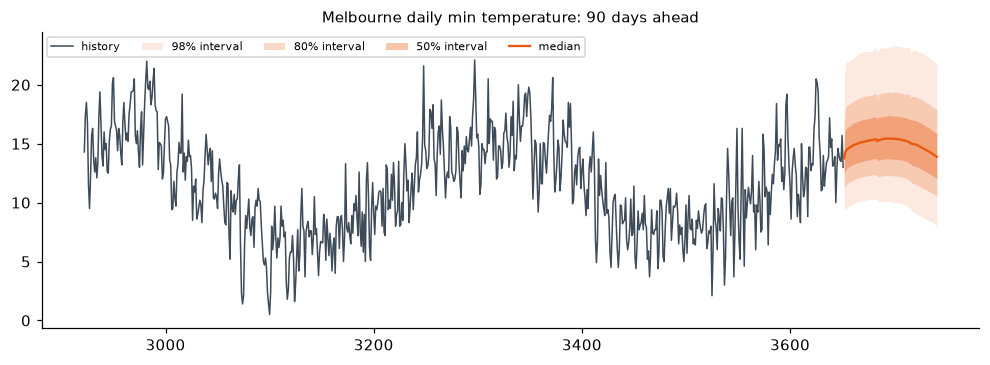

In [10]:
ctx, ids, last_ts = frame_to_context(temps, freq="D")
fc_temp = forecaster.forecast(ctx, prediction_length=90)
out = forecast_to_frame(fc_temp, ids, last_ts, freq="D")
print(out.head())

ax = plot_forecast(ctx[0], fc_temp, n_hist=730, title="Melbourne daily min temperature: 90 days ahead")
plt.show()

Hold-out check on a second public dataset: the classic monthly airline passengers (1949-1960, only 144 points).
We hide the last 24 months and compare with the truth. Short histories work, but the model can only extrapolate
patterns that are visible in the context.

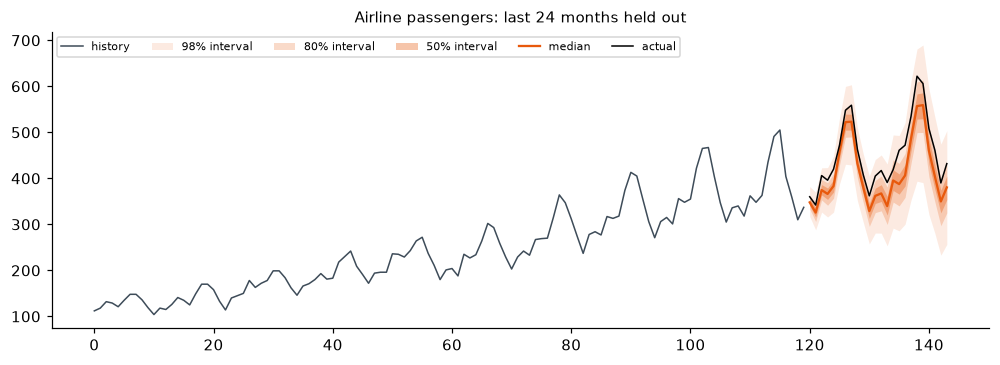

In [11]:
air = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv")
y_air = air["Passengers"].to_numpy(dtype=np.float32)
fc_air = forecaster.forecast(y_air[:-24], prediction_length=24)
plot_forecast(y_air[:-24], fc_air, future=y_air[-24:], title="Airline passengers: last 24 months held out")
plt.show()

## 5. Multivariate: variates of one series forecast jointly

With shape `(B, V, T)` the V variates of each series attend to each other, so the model can use one variate's
recent movement to forecast another (e.g. the 3 phases of a transformer load, or temperature + humidity of a
sensor). All V variates are *targets*: each gets its own forecast.

quantiles: (1, 2, 24, 21)
follower MAE, forecast alone  : 1.41
follower MAE, forecast jointly: 0.90


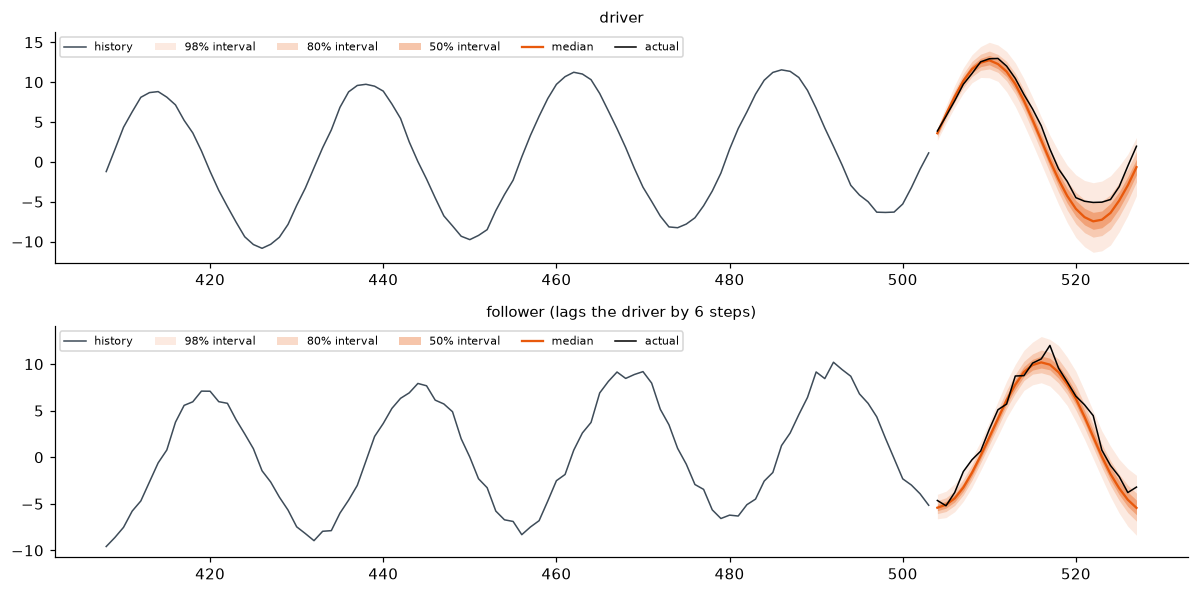

In [12]:
T, H = 24 * 21, 24
t = np.arange(T + H)
driver = 10 * np.sin(2 * np.pi * t / 24) + np.cumsum(rng.normal(0, 0.3, t.size))
follower = 0.8 * np.roll(driver, 6) + rng.normal(0, 0.5, t.size)  # follows the driver with a 6-step lag
mv = np.stack([driver, follower])[None]                             # (1, 2, T + H)

fc_mv = forecaster.forecast(mv[..., :T], prediction_length=H)       # joint
fc_uv = forecaster.forecast(mv[0, 1:, :T], prediction_length=H)     # follower alone, (1, T)

err = lambda f: np.mean(np.abs(f - mv[0, 1, T:]))                   # noqa: E731
print("quantiles:", tuple(fc_mv.quantiles.shape))
print(f"follower MAE, forecast alone  : {err(fc_uv.median[0, 0].numpy()):.2f}")
print(f"follower MAE, forecast jointly: {err(fc_mv.median[0, 1].numpy()):.2f}")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))
for v, ax in enumerate(axes):
    plot_forecast(mv[0, v, :T], fc_mv, future=mv[0, v, T:], variate=v, n_hist=24 * 4, ax=ax,
                  title=["driver", "follower (lags the driver by 6 steps)"][v])
plt.tight_layout()
plt.show()

## 6. Covariates

Covariates are **conditioning rows**: they inform the target forecast but are not forecast themselves.

| Argument | Shape | Known over | Examples |
|---|---|---|---|
| `past_covariates` | `(B, C, T)` | context only | footfall, competitor price observed, sensor readings |
| `known_covariates` | `(B, C, T + H)` | context **and horizon** | promotions, planned price, calendar, weather *forecast* |
| `categorical_past_covariates` | `(B, C, T)` | context only | category codes |
| `categorical_known_covariates` | `(B, C, T + H)` | context and horizon | holiday type, day of week, store event |

Notes from the library: known covariates whose values are all 0/1 are treated as indicators; categories are passed
as numeric codes (e.g. `pandas.factorize`) and target-encoded per series; NaN marks a missing covariate value.

**Example**: daily sales of 20 products with promotions planned in advance (+40% uplift) and a holiday calendar.
The last 28 days are hidden; promotions inside the horizon are known.

In [13]:
n_items, T, H = 20, 365, 28
dates = pd.date_range("2025-01-01", periods=T + H, freq="D")
dow = dates.dayofweek.to_numpy()
holiday_type = np.zeros(T + H)                                            # 0 none, 1 public holiday, 2 sales event
holiday_type[rng.choice(T + H, 12, replace=False)] = 1
holiday_type[[60, 61, 200, 201, T + 10, T + 11]] = 2                      # a sales event inside the horizon

sales, promos = [], []
for i in range(n_items):
    base = rng.uniform(20, 200)
    promo = (rng.random(T + H) < 0.1).astype(np.float32)
    weekly = 1 + 0.3 * (dow >= 5)
    effect = 1 + 0.4 * promo + np.where(holiday_type == 2, 0.8, 0) - np.where(holiday_type == 1, 0.3, 0)
    sales.append(rng.poisson(base * weekly * effect).astype(np.float32))
    promos.append(promo)
sales, promos = np.stack(sales), np.stack(promos)                         # (20, T + H)

context = sales[:, :T]                                                    # (B, T): targets
known = promos[:, None, :]                                                # (B, 1, T + H): promo plan
cat_known = np.tile(holiday_type, (n_items, 1))[:, None, :]               # (B, 1, T + H): holiday codes

fc_none = forecaster.forecast(context, H)
fc_promo = forecaster.forecast(context, H, known_covariates=known)
fc_full = forecaster.forecast(context, H, known_covariates=known, categorical_known_covariates=cat_known)


def wql(fc, actual):
    """Weighted quantile loss over all series, horizon and the 21 levels (lower = better)."""
    qs = np.asarray(fc.quantile_levels)
    pred = fc.quantiles[:, 0].cpu().numpy()                                # (B, H, Q)
    u = actual[..., None] - pred
    loss = np.maximum(qs * u, (qs - 1) * u)
    return 2 * loss.mean(-1).sum() / np.abs(actual).sum()


actual = sales[:, T:]
for name, f in [("no covariates", fc_none), ("+ promo plan", fc_promo), ("+ promo + holiday codes", fc_full)]:
    mae = np.mean(np.abs(f.median[:, 0].numpy() - actual))
    print(f"{name:26s} MAE {mae:6.2f} | WQL {wql(f, actual):.4f}")

no covariates              MAE  19.05 | WQL 0.1159
+ promo plan               MAE  17.30 | WQL 0.1046
+ promo + holiday codes    MAE  15.79 | WQL 0.0950


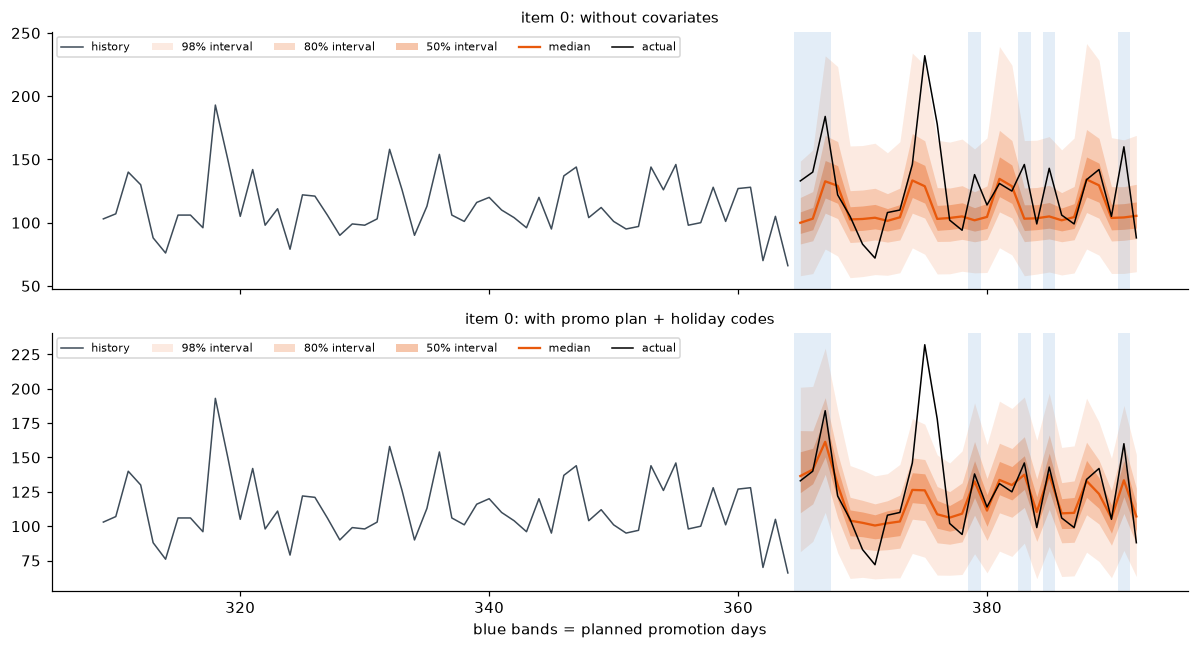

In [14]:
item = int(np.argmax(promos[:, T:].sum(1)))                               # the item with most promo days ahead
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, f, title in [(axes[0], fc_none, "without covariates"), (axes[1], fc_full, "with promo plan + holiday codes")]:
    plot_forecast(context[item], f, future=actual[item], series=item, n_hist=56, ax=ax, title=f"item {item}: {title}")
    for d in np.where(promos[item, T:] == 1)[0]:
        ax.axvspan(T + d - 0.5, T + d + 0.5, color="#1971c2", alpha=0.12, lw=0)
axes[1].set_xlabel("blue bands = planned promotion days")
plt.tight_layout()
plt.show()

In [15]:
# Past-only covariates: observed up to today, unknown in the future (e.g. store footfall)
footfall = (sales[:, :T] * rng.uniform(3, 4, (n_items, 1)) + rng.normal(0, 5, (n_items, T)))[:, None, :]
fc_past = forecaster.forecast(context, H, past_covariates=footfall, known_covariates=known)
print("with past footfall + promo plan: WQL", round(wql(fc_past, actual), 4))

with past footfall + promo plan: WQL 0.1056


## 7. Long horizons and forecaster options

* **Horizon**: one forward pass decodes up to `block_size × patch_size` = 1,024 steps. Longer horizons are produced
  block by block, feeding each block's median back as context, so uncertainty beyond 1,024 steps is less reliable.
* **`symmetric_averaging=True`** (default): averages the forecast of the series with the mirrored forecast of its
  negation; this makes the model treat ups and downs symmetrically. Turning it off halves the compute.
* **`clip_nonnegative=True`** (default): series whose history is entirely ≥ 0 get forecasts clipped at 0
  (sales, counts, energy). Turn it off for quantities that can become negative later (e.g. net flows).
* **`max_context`** (at load time): cap the context to speed up inference on very long series.

In [16]:
long_hist = y[: 24 * 7 * 6]
for H_long in [96, 1024, 2000]:
    t0 = time.perf_counter()
    f = forecaster.forecast(long_hist, H_long)
    print(f"horizon {H_long:5d}: {1000 * (time.perf_counter() - t0):7.1f} ms, output {tuple(f.quantiles.shape)}")

t0 = time.perf_counter(); forecaster.forecast(batch, 96); full = time.perf_counter() - t0
t0 = time.perf_counter(); forecaster.forecast(batch, 96, symmetric_averaging=False); half = time.perf_counter() - t0
print(f"symmetric averaging on: {1000 * full:.0f} ms | off: {1000 * half:.0f} ms")

fast = TimestralForecaster.from_pretrained(MODEL_ID, device=device, max_context=2048)
print("context cap of the fast forecaster:", fast.max_context)

horizon    96:    99.4 ms, output (1, 1, 96, 21)
horizon  1024:   139.2 ms, output (1, 1, 1024, 21)
horizon  2000:   309.8 ms, output (1, 1, 2000, 21)
symmetric averaging on: 168 ms | off: 88 ms


Fetching 2 files: 100%|██████████| 2/2 [00:00<?, ?it/s]

context cap of the fast forecaster: 2048


## 8. Backtesting: is it good on *your* data?

Never trust a benchmark alone. A **rolling-origin backtest** repeatedly hides the next H steps, forecasts them from
what came before, and scores the result. We use:

* **MASE**: mean absolute error of the median ÷ in-sample error of a seasonal-naive forecast (< 1 beats naive);
* **WQL**: weighted quantile loss over all quantiles, which scores the whole predictive distribution.

and compare model sizes with the seasonal-naive baseline on the temperature series.

In [17]:
def seasonal_naive(history, H, m):
    last = history[-m:]
    return np.array([last[h % m] for h in range(H)])


def mase(actual, pred, history, m):
    scale = np.nanmean(np.abs(history[m:] - history[:-m]))
    return np.mean(np.abs(actual - pred)) / scale


def backtest(series, H, n_windows, m, forecasters: dict):
    """Rolling-origin evaluation; returns mean MASE / WQL / time per model."""
    series = np.asarray(series, dtype=np.float32)
    rows = []
    for w in range(n_windows, 0, -1):
        cut = len(series) - w * H
        hist, actual = series[:cut], series[cut:cut + H]
        sn = seasonal_naive(hist, H, m)
        rows.append({"model": "seasonal naive", "MASE": mase(actual, sn, hist, m), "WQL": np.nan, "ms": 0.0})
        for name, f in forecasters.items():
            t0 = time.perf_counter()
            fc = f.forecast(hist, H)
            ms = 1000 * (time.perf_counter() - t0)
            rows.append({"model": name, "MASE": mase(actual, fc.median[0, 0].numpy(), hist, m),
                         "WQL": wql(fc, actual[None]), "ms": ms})
    return pd.DataFrame(rows).groupby("model", sort=False).mean().round(3)


candidates = {MODEL_ID.split("/")[-1]: forecaster}
for size in ["mistralai/Timestral-5M"]:  # add "mistralai/Timestral-209M" to compare the largest model
    candidates[size.split("/")[-1]] = TimestralForecaster.from_pretrained(size, device=device)

temp_series = temps.sort_values("timestamp")["value"].to_numpy()
backtest(temp_series, H=28, n_windows=12, m=365, forecasters=candidates)

Fetching 2 files: 100%|██████████| 2/2 [00:00<?, ?it/s]


,MASE,WQL,ms
model,,,
seasonal naive,0.910,NaN,0.000
Timestral-28M,0.621,0.123,159.007
Timestral-5M,0.622,0.123,47.299


Read it as: MASE < 1 means better than repeating last year's values; the WQL gap between sizes tells you whether
the larger model is worth its extra latency on this data.

## 9. Offline use and practical tips

**Air-gapped / on-prem.** Download once, copy the folder, load from disk:

```python
from huggingface_hub import snapshot_download
path = snapshot_download("mistralai/Timestral-209M", allow_patterns=["config.json", "model.safetensors"],
                         local_dir="models/Timestral-209M")
forecaster = TimestralForecaster.from_pretrained("models/Timestral-209M")   # no network needed
# or: TimestralForecaster.from_pretrained("mistralai/Timestral-209M", local_files_only=True)  # from the HF cache
```

**Tips and pitfalls**

* **Regular grid first.** The model assumes equally spaced steps. Resample irregular data and leave real gaps as NaN
  rather than dropping rows (dropping rows silently shifts the seasonality).
* **Enough context.** Show at least a few full cycles of the longest seasonality you need. For yearly patterns on
  daily data, give 2+ years.
* **No scaling needed.** Each series is normalised internally; feed raw values (no log/standardisation needed).
* **Batch for throughput.** Many series in one call is much faster than a loop; group series of similar length to
  limit padding.
* **Use the quantiles.** For stock or capacity decisions, plan on a quantile matching your service level
  (e.g. `fc.quantile(0.9)`), not on the median.
* **Covariates must be aligned.** `known_covariates` must cover `T + H` steps, exactly aligned with the context;
  an off-by-one shift is the most common silent bug. Only pass as "known" what you will really know at forecast time.
* **Fine-tuning** is not part of this library; Mistral offers domain adaptation through its Forge platform.
* **Licence:** check the weights' Modified MIT terms before shipping to a client.